# 🧰 Import pandas

In [2]:
import pandas as pd

# 📥 Load data 

In [3]:
expense_review_data = pd.read_csv("../data/raw/expenses_raw.csv")

In [4]:
expense_review_data

,Date,Description,Amount,Category,KnownAnomaly
0,2024-07-08,ALDI Joondalup Card,85.09,Groceries,0
1,2026-04-05,IGA Ellenbrook,26.79,Groceries,0
2,2025-12-31,ALDI Online Card,63.75,Groceries,0
3,2025-12-05,Local Cafe Balcatta AU,15.78,Dining,0
4,2025-02-03,GP Clinic Morley Mon,103.15,Health,0
...,...,...,...,...,...
2606,2025-09-17,Udemy Online AU,17.98,education,0
2607,2025-12-22,IGA Mon,77.28,Groceries,0
2608,2026-03-17,Coles Balcatta Purchase,83.08,Groceries,0
2609,2026-02-14,DiDi Cannington AU,17.64,Transport,0


# 🧼 Data cleaning 

In [5]:
# Create a copy of the raw dataset so the original data stays unchanged
expense_review_clean = expense_review_data.copy()

In [6]:
# Inspect the DataFrame
expense_review_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 2611 entries, 0 to 2610
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          2611 non-null   str    
 1   Description   2589 non-null   str    
 2   Amount        2601 non-null   float64
 3   Category      2598 non-null   str    
 4   KnownAnomaly  2611 non-null   int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 198.4 KB


In [7]:
# Check for missing values
expense_review_clean.isna().sum()

Date             0
Description     22
Amount          10
Category        13
KnownAnomaly     0
dtype: int64

In [8]:
# Check the percentage of missing values
expense_review_clean.isna().mean() * 100

Date            0.000000
Description     0.842589
Amount          0.382995
Category        0.497894
KnownAnomaly    0.000000
dtype: float64

In [9]:
# Remove rows with missing values in the required columns
expense_review_clean.dropna(
    subset=["Description", "Category", "Amount"],
    inplace=True
)

In [10]:
# Validate missing values
expense_review_clean.isna().sum()

Date            0
Description     0
Amount          0
Category        0
KnownAnomaly    0
dtype: int64

In [11]:
# Check for duplicate rows
expense_review_clean.duplicated().sum()

np.int64(25)

In [12]:
# Remove duplicate rows
expense_review_clean.drop_duplicates(
    inplace=True
)

In [13]:
# Validate duplicates
expense_review_clean.duplicated().sum()

np.int64(0)

In [14]:
# Convert the Date column to datetime format
expense_review_clean["Date"] = pd.to_datetime(
    expense_review_clean["Date"],
    errors="coerce"
)   

In [15]:
# Remove rows where Date could not be converted properly
expense_review_clean.dropna(
    subset=["Date"],
    inplace=True
)

In [16]:
# Keep only positive expense amounts
expense_review_clean.query(
    "Amount > 0",
    inplace=True
)

In [17]:
# Clean category text formatting
expense_review_clean["Category"] = (
    expense_review_clean["Category"]
    .str.strip()
    .str.title()
)

In [18]:
# Fix known category spelling errors
category_fixes = {
    "Groceriess": "Groceries",
    "Transports": "Transport",
    "Dinings": "Dining",
    "Billss": "Bills",
    "Entertainments": "Entertainment",
    "Shoppings": "Shopping",
    "Healths": "Health",
    "Educations": "Education",
    "Personal Cares": "Personal Care",
    "Travels": "Travel",
    "Others": "Other",
}
expense_review_clean["Category"] = (
    expense_review_clean["Category"]
    .replace(category_fixes)
)

In [19]:
# Clean description text by removing extra spaces
expense_review_clean["Description"] = (
    expense_review_clean["Description"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)


In [20]:
# Reset the index after cleaning so the row numbers are tidy
expense_review_clean.reset_index(
    drop=True, 
    inplace=True
)

# 🔍 Exploratory Data Analysis (EDA)

,Date,Description,Amount,Category,KnownAnomaly,Year,Month,Day,DayOfWeek,IsWeekend
count,2521,2521,2521.000000,2521,2521.000000,2521.000000,2521.000000,2521.000000,2521,2521
unique,NaN,1407,NaN,11,NaN,NaN,NaN,NaN,7,2
top,NaN,Rent Balcatta,NaN,Groceries,NaN,NaN,NaN,NaN,Friday,False
freq,NaN,65,NaN,577,NaN,NaN,NaN,NaN,426,1815
mean,2025-03-27 17:01:18.540261,NaN,82.788548,NaN,0.015470,2024.785799,5.944070,15.391115,NaN,NaN
min,2024-01-01 00:00:00,NaN,0.070000,NaN,0.000000,2024.000000,1.000000,1.000000,NaN,NaN
25%,2024-08-08 00:00:00,NaN,23.290000,NaN,0.000000,2024.000000,3.000000,8.000000,NaN,NaN
50%,2025-04-01 00:00:00,NaN,44.600000,NaN,0.000000,2025.000000,6.000000,15.000000,NaN,NaN
75%,2025-11-02 00:00:00,NaN,77.280000,NaN,0.000000,2025.000000,9.000000,23.000000,NaN,NaN
max,2026-06-27 00:00:00,NaN,4955.850000,NaN,1.000000,2026.000000,12.000000,31.000000,NaN,NaN


Category
Groceries        577
Bills            409
Dining           403
Transport        375
Shopping         269
Entertainment    179
Health           106
Education         68
Personal Care     60
Other             55
Travel            20
Name: count, dtype: int64

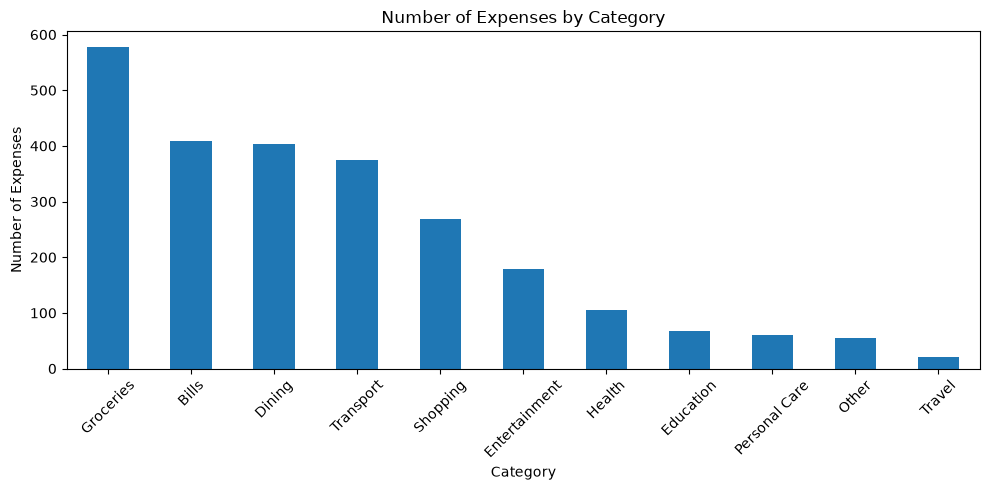

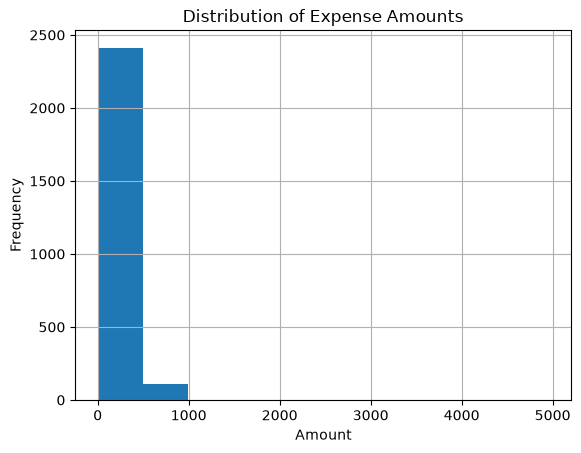

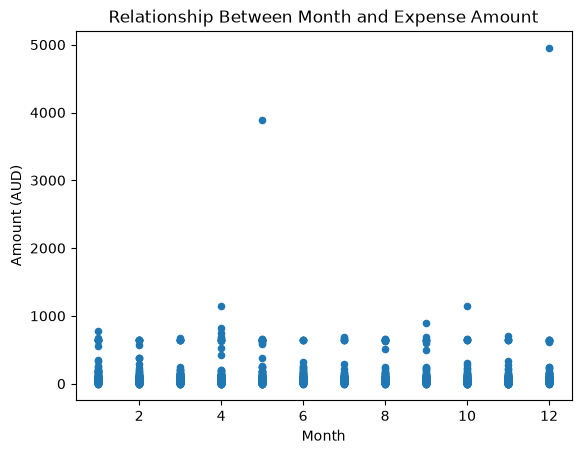

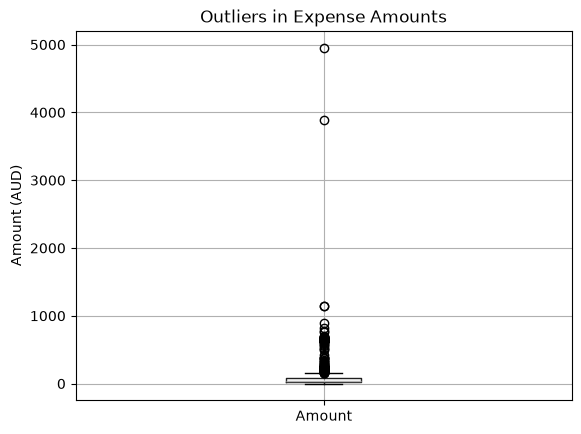

In [63]:
import matplotlib.pyplot as plt

# 1. View summary statistics
display(expense_review_clean.describe(include="all"))


# 2. Check the distribution of values in categorical columns
category_counts = expense_review_clean["Category"].value_counts()

display(category_counts)

category_counts.plot(
    kind="bar",
    figsize=(10, 5),
    title="Number of Expenses by Category"
)

plt.xlabel("Category")
plt.ylabel("Number of Expenses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Check the distribution of values in numerical columns
expense_review_clean["Amount"].hist()

plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Expense Amounts")
plt.show()

# 4. Check the relationship between two numerical columns
expense_review_clean.plot.scatter(x="Month", y="Amount")

plt.xlabel("Month")
plt.ylabel("Amount (AUD)")
plt.title("Relationship Between Month and Expense Amount")
plt.show()


# 5. Check for outliers in numerical columns
expense_review_clean.boxplot(column="Amount")

plt.ylabel("Amount (AUD)")
plt.title("Outliers in Expense Amounts")
plt.show()



## EDA Findings and Conclusions

### 1. Summary Statistics


The dataset contains 2,521 expenses (from the count row) across 11 categories (from the unique row under Category).

The average expense is $82.79 (from the mean row under Amount), while the median is $44.60 (from the 50% row).

The median is the middle value when all expenses are arranged from smallest to largest.

Because the average is much higher than the median, this suggests that the data is right-skewed. This simply means most expenses are relatively small, but some very large expenses are pulling the average up.

The smallest expense is $0.07 (from the min row under Amount), while the largest is $4,955.85 (from the max row).

### Why This Matters

These findings show that expense amounts vary a lot, with some being much larger than others.

This matters because very large values can affect how some machine learning models learn, especially regression and anomaly detection models.

However, large expenses are not necessarily errors. They could be real transactions, so we should not automatically remove them.


### 2. Categorical Distributions

The dataset contains 11 expense categories.

Groceries is the most common category, with 577 expenses, while Travel is the least common, with only 20 expenses (from the category counts).

This means our dataset has class imbalance. Class imbalance simply means some categories have many more examples than others.

### Why This Matters

Our classification model is trained to predict expense categories.

Because Groceries has 577 examples and Travel has only 20, the model has much fewer Travel examples to learn from.

This could make it harder for the model to predict less common categories correctly.

This is why we use stratified splitting to keep similar category proportions in our training and testing data.

We also use macro F1-score to check how well the model performs across all categories, rather than relying only on overall accuracy.

Class weighting can also be tested to see whether giving more importance to less common categories improves performance.

### 3. Numerical Distributions

The histogram shows how expense amounts are distributed.

The horizontal axis (Amount) shows the expense amounts in dollars.

The vertical axis (Frequency) shows how many expenses fall within each amount range.

Each bar represents a range of expense amounts. The taller the bar, the more expenses fall within that range.

Most expenses are grouped in the first bar, which represents amounts from approximately $0 to $500.

There are very few expenses above $500, which explains why the remaining bars are barely visible.

This means the data is right-skewed. Right-skewed simply means most values are relatively small, while a few very large values stretch the distribution towards the right.

### Why This Matters

The histogram confirms what we noticed in our basic statistics: most expenses are small, but a few are much larger.

These large values could affect some machine learning models, especially our regression model, which predicts expense amounts.

For example, the regression model might make larger prediction errors on expensive transactions.

However, right-skewed data is not automatically a problem. We should only make changes if testing shows they improve model performance.

### 4. Bivariate Analysis

### Findings

The scatter plot shows the relationship between the month and expense amount.

The horizontal axis (Month) shows the months of the year, from 1 (January) to 12 (December).

The vertical axis (Amount) shows how much was spent in Australian dollars.

Each dot represents an expense. The position of the dot tells us which month the expense occurred and how much it cost.

Most dots are grouped near the bottom of the chart. This means most expenses are relatively small throughout the year.

However, there are a few unusually large expenses. For example, May has an expense of approximately $3,900, while December has one close to $5,000.

There is no clear relationship between month and expense amount. Expenses do not consistently increase or decrease as the months change.

### Why This Matters

These findings suggest that the month alone may not be a strong predictor of expense amount.

For our regression model, which predicts expense amounts, this means the Month column might not provide much useful information on its own.

However, the scatter plot does not prove that Month is useless. Our model might still find useful patterns when Month is combined with other features.

We can compare model performance to determine whether including Month actually helps.

### 5. Outlier Detection

The boxplot shows the distribution of expense amounts and helps identify possible outliers.

Outliers are values that are unusually high or low compared to most other values.

The box represents the middle 50% of expenses, while the line inside the box represents the median (middle value).

The lines extending from the box are called whiskers. They show the range of values that are not considered outliers by the boxplot's method.

The individual dots outside the whiskers represent potential outliers.

Most expenses are relatively small, which is why the box is compressed near the bottom of the chart.

However, there are many dots above the whiskers, including expenses around $1,100, $3,900 and $5,000.

This tells us that some expenses are unusually large compared to the majority.

### Why This Matters

These findings confirm that our dataset contains potential outliers.

This matters because unusually large values could affect how some machine learning models learn, especially our regression model, which predicts expense amounts.

Outliers are also important for our anomaly detection model, which is designed to identify unusual expenses.

However, an outlier is not automatically an error or an anomaly. For example, a $5,000 expense could be a legitimate purchase.

Therefore, we should not automatically remove these values. Whether they need special treatment depends on the model and our evaluation results.

# 🛠️ Feature engineering

In [22]:
# Create date-based columns from the Date column
expense_review_clean["Year"] = expense_review_clean["Date"].dt.year
expense_review_clean["Month"] = expense_review_clean["Date"].dt.month
expense_review_clean["Day"] = expense_review_clean["Date"].dt.day
expense_review_clean["DayOfWeek"] = expense_review_clean["Date"].dt.day_name()
expense_review_clean["IsWeekend"] = expense_review_clean["Date"].dt.weekday >= 5

In [23]:
# Create features and target
X_category = expense_review_clean[
 [
    "Description",
    "Amount",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "IsWeekend",
 ]   
]

y_category = expense_review_clean["Category"]

In [24]:
# Save the processed dataset 
expense_review_clean.to_csv(
    "../data/processed/expense_review_clean.csv",
    index=False
)

In [25]:
# Import the Scikit-learn tool used to split data into training and testing sets
from sklearn.model_selection import train_test_split

 # Split the data into training and testing sets
(
      X_category_train,
      X_category_test,
      y_category_train,
      y_category_test,
) = train_test_split(
      X_category,
      y_category,
      test_size=0.2,
      random_state=42,
      stratify=y_category
   )

    
     

  

In [26]:
# Import tools for transforming different feature types
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Group the features by data type
text_columns = "Description"

numeric_columns = [
    "Amount",
    "Year",
    "Month",
    "Day",
    "IsWeekend",
]

categorical_columns = ["DayOfWeek"]

# Create a variable called preprocessor to store all the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(), text_columns),
        ("numbers", StandardScaler(), numeric_columns),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [27]:
# Import tools for creating the model pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create a pipeline that preprocesses the features and uses Logistic Regression
category_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# 🎓 Train the model

In [28]:
category_model.fit(X_category_train, y_category_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['Bills','Dining','Education',...,'Shopping','Transport','Travel']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Description','Amount','Year',...,'Day','DayOfWeek','IsWeekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('numbers', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defau

# 🧪 Test the model

In [29]:
y_category_pred = category_model.predict(X_category_test)

# 📊 Evaluate the model

In [30]:
# Import the tool used to calculate classification accuracy
from sklearn.metrics import accuracy_score

# Compare the model's predictions with the correct answers
category_accuracy = accuracy_score(
    y_category_test,
    y_category_pred
)

# Display the accuracy as a percentage
print(f"Category model accuracy: {category_accuracy:.2%}")

Category model accuracy: 98.61%


In [31]:
# Import the tool used to create a  classification report
from sklearn.metrics import classification_report

# Compare the correct answers with the model's predictions
print(classification_report(
    y_category_test, 
    y_category_pred
    ))

               precision    recall  f1-score   support

        Bills       0.92      1.00      0.96        82
       Dining       1.00      0.99      0.99        81
    Education       1.00      0.86      0.92        14
Entertainment       1.00      1.00      1.00        36
    Groceries       1.00      1.00      1.00       115
       Health       1.00      1.00      1.00        21
        Other       1.00      1.00      1.00        11
Personal Care       1.00      1.00      1.00        12
     Shopping       1.00      1.00      1.00        54
    Transport       1.00      0.99      0.99        75
       Travel       1.00      0.25      0.40         4

     accuracy                           0.99       505
    macro avg       0.99      0.92      0.93       505
 weighted avg       0.99      0.99      0.98       505



# ⚔️ Compare Classification Algorithmsm

In [32]:
# Import the additional classification algorithms
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import the tool used to calculate the F1 score
from sklearn.metrics import f1_score

# Import the tool used to create fresh copies of the preprocessor
from sklearn.base import clone

# Create the classification algorithms we want to compare
classification_algorithms = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
    ),
}

# Create containers to store the results and trained models
classification_results = []
trained_category_models = {}

# Train and evaluate each classification algorithm
for model_name, algorithm in classification_algorithms.items():

    # Create another pipeline for the different classification algorithms
    comparison_pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", algorithm),
        ]
    )

    # Train each classification model
    comparison_pipeline.fit(
        X_category_train,
        y_category_train,
    )

    # Test each classification model
    model_predictions = comparison_pipeline.predict(
        X_category_test
    )

    # Calculate the accuracy for each model
    model_accuracy = accuracy_score(
        y_category_test,
        model_predictions,
    )

    # Calculate the Macro F1 score for each model
    model_macro_f1 = f1_score(
        y_category_test,
        model_predictions,
        average="macro",
    )

    # Store the results
    classification_results.append(
        {
            "Model": model_name,
            "Macro F1 Score": model_macro_f1,
            "Accuracy": model_accuracy,
        }
    )

    # Store the trained pipeline
    trained_category_models[model_name] = comparison_pipeline


# Convert the results into a pandas DataFrame
classification_results_df = pd.DataFrame(
    classification_results
)

# Sort the models from highest to lowest Macro F1 score
classification_results_df = classification_results_df.sort_values(
    "Macro F1 Score",
    ascending=False,
).reset_index(drop=True)

# Display the scores as percentages
classification_results_df.style.format(
    {
        "Macro F1 Score": "{:.2%}",
        "Accuracy": "{:.2%}",
    }
)

,Model,Macro F1 Score,Accuracy
0,Linear SVM,96.88%,99.60%
1,Random Forest,96.80%,99.60%
2,Decision Tree,96.15%,99.21%
3,Logistic Regression,93.36%,98.61%


# 🔄 Cross-Validation

In [33]:
# Import the tools used for cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create the cross-validation setup
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Choose the metrics used to compare the models
cross_validation_scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
}

# Create a list to store the cross-validation results
cross_validation_results = []

# Compare each classification algorithm using cross-validation
for model_name, algorithm in classification_algorithms.items():


    # Create a fresh pipeline for cross-validation 
    cross_validation_pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", clone(algorithm)),
        ]
    )

    # Train and predict the model across the five folds
    fold_scores = cross_validate(
        estimator=cross_validation_pipeline,
        X=X_category_train,
        y=y_category_train,
        cv=cross_validation,
        scoring=cross_validation_scoring,
    )

    # Store the average scores and standard deviations
    cross_validation_results.append(
        {
            "Model": model_name,
            "Mean Macro F1": fold_scores["test_macro_f1"].mean(),
            "Macro F1 Standard Deviation": fold_scores["test_macro_f1"].std(),
            "Mean Accuracy": fold_scores["test_accuracy"].mean(),
            "Accuracy Standard Deviation": fold_scores["test_accuracy"].std(),
        }
    )

# Convert the results into a pandas DataFrame
cross_validation_results_df = pd.DataFrame(
    cross_validation_results
)

# Sort the models from highest to lowest Mean Macro F1 score
cross_validation_results_df = (
    cross_validation_results_df
    .sort_values("Mean Macro F1", ascending=False)
    .reset_index(drop=True)
)

# Display the scores as percentages
cross_validation_results_df.style.format(
    {
        "Mean Macro F1": "{:.2%}",
        "Macro F1 Standard Deviation": "{:.2%}",
        "Mean Accuracy": "{:.2%}",
        "Accuracy Standard Deviation": "{:.2%}",
    }
)

,Model,Mean Macro F1,Macro F1 Standard Deviation,Mean Accuracy,Accuracy Standard Deviation
0,Linear SVM,100.00%,0.00%,100.00%,0.00%
1,Random Forest,98.73%,1.06%,99.75%,0.27%
2,Logistic Regression,95.50%,3.02%,99.36%,0.20%
3,Decision Tree,95.00%,2.98%,98.76%,0.42%


# 🔧 Hyperparameter Tuning

In [34]:
# Import the tool used for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Create a fresh Linear SVM pipeline for tuning
linear_svm_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LinearSVC(random_state=42)),
    ]
)

# Choose the hyperparameter values to test
linear_svm_parameter_grid = {
    "preprocessor__text__ngram_range": [
        (1, 1),
        (1, 2),
    ],
    "preprocessor__text__min_df": [
        1,
        2,
    ],
    "model__C": [
        0.01,
        0.1,
        1,
        10,
    ],
}

# Create the grid search
linear_svm_grid_search = GridSearchCV(
    estimator=linear_svm_tuning_pipeline,
    param_grid=linear_svm_parameter_grid,
    scoring="f1_macro",
    cv=cross_validation,
    n_jobs=-1,
    refit=True,
)

# Train the model using different hyperparameter combinations with cross-validation
linear_svm_grid_search.fit(
    X_category_train,
    y_category_train,
)

# Display the best hyperparameters
print("Best parameters:")
print(linear_svm_grid_search.best_params_)

# Store the best trained Linear SVM model
best_linear_svm_model = linear_svm_grid_search.best_estimator_

# Make predictions using the final tuned model
y_category_tuned_pred = best_linear_svm_model.predict(
    X_category_test
)

# Display the final accuracy
print("Tuned Linear SVM Accuracy:")
print(
    accuracy_score(
        y_category_test,
        y_category_tuned_pred,
    )
)

# Display the final classification report
print("\nTuned Linear SVM Classification Report:")
print(
    classification_report(
        y_category_test,
        y_category_tuned_pred,
    )
)

Best parameters:
{'model__C': 1, 'preprocessor__text__min_df': 1, 'preprocessor__text__ngram_range': (1, 1)}
Tuned Linear SVM Accuracy:
0.996039603960396

Tuned Linear SVM Classification Report:
               precision    recall  f1-score   support

        Bills       0.99      1.00      0.99        82
       Dining       1.00      1.00      1.00        81
    Education       1.00      1.00      1.00        14
Entertainment       1.00      1.00      1.00        36
    Groceries       0.99      1.00      1.00       115
       Health       1.00      1.00      1.00        21
        Other       1.00      1.00      1.00        11
Personal Care       1.00      1.00      1.00        12
     Shopping       1.00      1.00      1.00        54
    Transport       1.00      1.00      1.00        75
       Travel       1.00      0.50      0.67         4

     accuracy                           1.00       505
    macro avg       1.00      0.95      0.97       505
 weighted avg       1.00      1.0

# 💾 Save the final category model

In [35]:
# Import the tool used to save trained models
import joblib

# Save the final tuned Linear SVM pipeline
joblib.dump(
    best_linear_svm_model,
    "../trained_models/expense_category_model.joblib"
)

['../trained_models/expense_category_model.joblib']

# 🔢 Regression 

In [36]:
# Create the features and target for amount prediction

X_amount = expense_review_clean[
    [
        "Description",
        "Category",
        "Year",
        "Month",
        "Day",
        "DayOfWeek",
        "IsWeekend"
    ]
] 

y_amount = expense_review_clean["Amount"]


In [37]:
# Split the amount data into training and test sets

X_amount_train, X_amount_test, y_amount_train, y_amount_test = train_test_split(
    X_amount, 
    y_amount, 
    test_size=0.2, 
    random_state=42
)


In [38]:
# Group the regression features by data type

amount_text_column = [
    "Description"
]

amount_numeric_columns = [
    "Year",
    "Month",
    "Day",
    "IsWeekend"
]

amount_categorical_columns = [
    "Category",
    "DayOfWeek"
]

# Create the preprocessing steps for the amount model

amount_preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(), "Description"),
        ("numbers", StandardScaler(), amount_numeric_columns),
        ("categories", OneHotEncoder(handle_unknown="ignore"), amount_categorical_columns)
    ]
)

In [39]:
# Import the regression algorithms
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor


# Create the regression algorithms to compare
regression_algorithms = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Import the tools used for cross-validation
from sklearn.model_selection import KFold, cross_validate


# Create the cross-validation setup
amount_cross_validation = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)


# Choose the metrics used to compare the models
amount_cross_validation_scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}


# Create a list to store the cross-validation results
amount_cross_validation_results = []


# Compare each regression algorithm using cross-validation
for model_name, algorithm in regression_algorithms.items():

    # Create a pipeline for cross-validation
    amount_cross_validation_pipeline = Pipeline(
        steps=[
            ("preprocessor", amount_preprocessor),
            ("model", algorithm),
        ]
    )

    # Train and predict the model across the five folds
    fold_scores = cross_validate(
        estimator=amount_cross_validation_pipeline,
        X=X_amount_train,
        y=y_amount_train,
        cv=amount_cross_validation,
        scoring=amount_cross_validation_scoring,
    )

    # Store the average scores and standard deviations
    amount_cross_validation_results.append(
        {
            "Model": model_name,
            "Mean MAE": -fold_scores["test_mae"].mean(),
            "MAE Standard Deviation": fold_scores["test_mae"].std(),
            "Mean RMSE": -fold_scores["test_rmse"].mean(),
            "RMSE Standard Deviation": fold_scores["test_rmse"].std(),
            "Mean R²": fold_scores["test_r2"].mean(),
            "R² Standard Deviation": fold_scores["test_r2"].std(),
        }
    )


# Convert the results into a pandas DataFrame
amount_cross_validation_results_df = pd.DataFrame(
    amount_cross_validation_results
)


# Sort the models from lowest to highest Mean MAE
amount_cross_validation_results_df = (
    amount_cross_validation_results_df
    .sort_values("Mean MAE", ascending=True)
    .reset_index(drop=True)
)


# Display the scores
amount_cross_validation_results_df.style.format(
    {
        "Mean MAE": "${:.2f}",
        "MAE Standard Deviation": "${:.2f}",
        "Mean RMSE": "${:.2f}",
        "RMSE Standard Deviation": "${:.2f}",
        "Mean R²": "{:.3f}",
        "R² Standard Deviation": "{:.3f}",
    }
)

,Model,Mean MAE,MAE Standard Deviation,Mean RMSE,RMSE Standard Deviation,Mean R²,R² Standard Deviation
0,Ridge Regression,$29.92,$3.38,$82.10,$52.09,0.712,0.199
1,Random Forest,$29.95,$3.85,$99.23,$45.56,0.563,0.208
2,Linear Regression,$35.29,$6.00,$102.40,$53.32,0.505,0.343
3,Decision Tree,$41.10,$5.05,$149.54,$46.01,-0.129,0.689


In [40]:
# Import the tool used for hyperparameter tuning
from sklearn.model_selection import GridSearchCV


# Create a fresh Ridge Regression pipeline for tuning
ridge_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", amount_preprocessor),
        ("model", Ridge()),
    ]
)


# Create the hyperparameter settings to test
ridge_parameter_grid = {
    "preprocessor__text__ngram_range": [
        (1, 1),
        (1, 2),
    ],

    "preprocessor__text__min_df": [
        1,
        2,
    ],

    "model__alpha": [
        0.01,
        0.1,
        1,
        10,
        100,
    ],
}


# Create the grid search
ridge_grid_search = GridSearchCV(
    estimator=ridge_tuning_pipeline,
    param_grid=ridge_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=amount_cross_validation,
    n_jobs=-1,
    refit=True,
)


# Run the grid search using the training data
ridge_grid_search.fit(
    X_amount_train,
    y_amount_train,
)


# Display the best hyperparameter settings
print("Best parameters:")
print(ridge_grid_search.best_params_)


# Get the final tuned Ridge Regression model
best_ridge_model = ridge_grid_search.best_estimator_


# Make predictions using the test data
y_amount_tuned_pred = best_ridge_model.predict(
    X_amount_test
)

# Import the tools used to evaluate the regression model
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Evaluate the tuned Ridge Regression model
print("Tuned Ridge Regression MAE:")
print(mean_absolute_error(y_amount_test, y_amount_tuned_pred))

print("\nTuned Ridge Regression RMSE:")
print(root_mean_squared_error(y_amount_test, y_amount_tuned_pred))

print("\nTuned Ridge Regression R²:")
print(r2_score(y_amount_test, y_amount_tuned_pred))

Best parameters:
{'model__alpha': 1, 'preprocessor__text__min_df': 1, 'preprocessor__text__ngram_range': (1, 1)}
Tuned Ridge Regression MAE:
35.503133129241

Tuned Ridge Regression RMSE:
203.95631359378046

Tuned Ridge Regression R²:
0.37352096245325017


In [41]:
# Save the final tuned Ridge Regression model

joblib.dump(
    best_ridge_model,
    "../trained_models/expense_amount_model.joblib"
)


['../trained_models/expense_amount_model.joblib']

# 🫧 Clustering 

In [42]:
# Choose the features used to discover spending patterns

X_clustering = expense_review_clean[
    [
        "Description",
        "Amount",
        "Category",
        "Year",
        "Month",
        "Day",
        "DayOfWeek",
        "IsWeekend"
    ]
]   



In [43]:
# Group the clustering features by data type

clustering_text_columns = [
    "Description"
]

clustering_numeric_columns = [
    "Amount",
    "Year",
    "Month",
    "Day",
    "IsWeekend"
]

clustering_categorical_columns = [
    "Category",
    "DayOfWeek"
]


# Create the preprocessing steps for clustering

clustering_preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(), "Description"),
        ("numbers", StandardScaler(), clustering_numeric_columns),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            clustering_categorical_columns
        )
    ]
)

In [44]:
# Fit and transform the clustering features

X_clustering_prepared = clustering_preprocessor.fit_transform(
    X_clustering
)

# Convert the prepared features to a normal array
X_clustering_prepared = X_clustering_prepared.toarray()

In [45]:
# Import the clustering algorithms
from sklearn.cluster import (
    KMeans,
    MiniBatchKMeans,
    AgglomerativeClustering
)


# Create the clustering algorithms to compare
clustering_algorithms = {
    "K-Means": KMeans(
        n_clusters=5,
        random_state=42,
        n_init="auto"
    ),

    "MiniBatch K-Means": MiniBatchKMeans(
        n_clusters=5,
        random_state=42,
        n_init="auto"
    ),

    "Agglomerative Clustering": AgglomerativeClustering(
        n_clusters=5
    )
}


# Import the clustering evaluation metric
from sklearn.metrics import silhouette_score


# Create an empty list to store the comparison results
clustering_comparison_results = []


# Compare each clustering algorithm
for model_name, algorithm in clustering_algorithms.items():

    # Train the algorithm and assign each expense to a cluster
    cluster_labels = algorithm.fit_predict(
        X_clustering_prepared
    )

    # Calculate the Silhouette Score
    silhouette = silhouette_score(
        X_clustering_prepared,
        cluster_labels
    )

    # Store the model name and Silhouette Score
    clustering_comparison_results.append(
        {
            "Model": model_name,
            "Silhouette Score": silhouette
        }
    )


# Convert the results into a DataFrame
clustering_comparison_results_df = pd.DataFrame(
    clustering_comparison_results
)


# Sort the models from highest to lowest Silhouette Score
clustering_comparison_results_df = (
    clustering_comparison_results_df
    .sort_values(
        "Silhouette Score",
        ascending=False
    )
    .reset_index(drop=True)
)


# Display the Silhouette Score to 3 decimal places
clustering_comparison_results_df.style.format(
    {
        "Silhouette Score": "{:.3f}"
    }
)

,Model,Silhouette Score
0,Agglomerative Clustering,0.154
1,K-Means,0.141
2,MiniBatch K-Means,0.130


In [46]:
# Create an empty list to store the tuning results
agglomerative_tuning_results = []


# Try different numbers of clusters
for number_of_clusters in range(2, 11):

    # Create the Agglomerative Clustering model
    agglomerative_model = AgglomerativeClustering(
        n_clusters=number_of_clusters
    )

    # Learn from the data and group the expenses
    cluster_labels = agglomerative_model.fit_predict(
        X_clustering_prepared
    )

    # Calculate the Silhouette Score
    silhouette = silhouette_score(
        X_clustering_prepared,
        cluster_labels
    )

    # Store the number of clusters and Silhouette Score
    agglomerative_tuning_results.append(
        {
            "Number of Clusters": number_of_clusters,
            "Silhouette Score": silhouette
        }
    )


# Convert the tuning results into a DataFrame
agglomerative_tuning_results_df = pd.DataFrame(
    agglomerative_tuning_results
)


# Sort from highest to lowest Silhouette Score
agglomerative_tuning_results_df = (
    agglomerative_tuning_results_df
    .sort_values(
        "Silhouette Score",
        ascending=False
    )
    .reset_index(drop=True)
)


# Display the Silhouette Score to 3 decimal places
agglomerative_tuning_results_df.style.format(
    {
        "Silhouette Score": "{:.3f}"
    }
)

,Number of Clusters,Silhouette Score
0,3,0.198
1,2,0.176
2,5,0.154
3,4,0.150
4,6,0.126
5,7,0.125
6,8,0.110
7,9,0.103
8,10,0.099


In [47]:
# Create the final Agglomerative Clustering model
best_agglomerative_model = AgglomerativeClustering(
    n_clusters=3
)

# Learn from the data and group the expenses
best_cluster_labels = best_agglomerative_model.fit_predict(
    X_clustering_prepared
)

In [48]:
# Create a copy of the cleaned expense data for clustering analysis
clustering_results = expense_review_clean.copy()

# Add each expense's cluster name to the data
clustering_results["Cluster"] = best_cluster_labels

# Summarise the Amount column for each cluster
cluster_summary = clustering_results.groupby("Cluster").agg(
    Number_of_Expenses=("Amount", "count"),
    Average_Amount=("Amount", "mean")
)

# Display the Amount summary for each cluster
cluster_summary

,Number_of_Expenses,Average_Amount
Cluster,,
0,1717,53.184030
1,695,54.467468
2,109,729.706972


In [49]:
# Count the categories inside each cluster
cluster_category_summary = (
    clustering_results
    .groupby(["Cluster", "Category"])
    .size()
    .reset_index(name="Number_of_Expenses")
)

# Display the results
cluster_category_summary

,Cluster,Category,Number_of_Expenses
0,0,Bills,237
1,0,Dining,271
2,0,Education,48
3,0,Entertainment,126
4,0,Groceries,401
5,0,Health,82
6,0,Other,40
7,0,Personal Care,41
8,0,Shopping,191
9,0,Transport,268


In [50]:
# Count weekday and weekend expenses inside each cluster
cluster_weekend_summary = (
    clustering_results
    .groupby(["Cluster", "IsWeekend"])
    .size()
    .reset_index(name="Number_of_Expenses")
)

# Display the results
cluster_weekend_summary

,Cluster,IsWeekend,Number_of_Expenses
0,0,False,1717
1,1,True,695
2,2,False,98
3,2,True,11


In [51]:
# Count the days of the week inside each cluster
cluster_day_summary = (
    clustering_results
    .groupby(["Cluster", "DayOfWeek"])
    .size()
    .reset_index(name="Number_of_Expenses")
)

# Display the results
cluster_day_summary

,Cluster,DayOfWeek,Number_of_Expenses
0,0,Friday,358
1,0,Monday,349
2,0,Thursday,327
3,0,Tuesday,340
4,0,Wednesday,343
5,1,Saturday,363
6,1,Sunday,332
7,2,Friday,68
8,2,Monday,8
9,2,Saturday,6


In [52]:
# Import joblib so we can save the clustering work
import joblib


# Store the fitted preprocessor and clustering model together
clustering_artifact = {
    "preprocessor": clustering_preprocessor,
    "model": best_agglomerative_model
}


# Save the clustering artifact
joblib.dump(
    clustering_artifact,
    "../trained_models/expense_clustering_model.joblib"
)


['../trained_models/expense_clustering_model.joblib']

# 🚨 Anomaly Detection

In [53]:
# Choose the features for anomaly detection
X_anomaly = expense_review_clean[
    [
        "Description",
        "Amount",
        "Category",
        "Year",
        "Month",
        "Day",
        "DayOfWeek",
        "IsWeekend"
    ]
]

In [54]:
# Split the anomaly detection data
X_anomaly_train, X_anomaly_test = train_test_split(
    X_anomaly,
    test_size=0.2,
    random_state=42
)

In [55]:
# Group the anomaly detection features by data type

anomaly_text_columns = [
    "Description"
]

anomaly_numeric_columns = [
    "Amount",
    "Year",
    "Month",
    "Day",
    "IsWeekend"
]

anomaly_categorical_columns = [
    "Category",
    "DayOfWeek"
]


# Create the preprocessing steps for anomaly detection

anomaly_preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(), "Description"),
        ("numbers", StandardScaler(), anomaly_numeric_columns),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            anomaly_categorical_columns
        )
    ]
)

In [56]:
# Import the anomaly detection algorithms
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM


# Create the anomaly detection algorithms to compare
anomaly_algorithms = {
    "Isolation Forest": IsolationForest(
        contamination=0.05,
        random_state=42
    ),

    "Local Outlier Factor": LocalOutlierFactor(
        contamination=0.05,
        novelty=True
    ),

    "One-Class SVM": OneClassSVM(
        nu=0.05
    )
}
# Compare the anomaly detection algorithms

anomaly_comparison_results = []
anomaly_predictions = {}
anomaly_trained_models = {}

for model_name, algorithm in anomaly_algorithms.items():

    anomaly_pipeline = Pipeline(
        steps=[
            ("preprocessor", anomaly_preprocessor),
            ("model", algorithm)
        ]
    )

    anomaly_pipeline.fit(X_anomaly_train)

    predictions = anomaly_pipeline.predict(
        X_anomaly_test
    )

    number_of_anomalies = (predictions == -1).sum()

    anomaly_percentage = (
        number_of_anomalies / len(predictions)
    ) * 100

    anomaly_comparison_results.append(
        {
            "Model": model_name,
            "Number of Anomalies": number_of_anomalies,
            "Anomaly Percentage": anomaly_percentage
        }
    )

    anomaly_predictions[model_name] = predictions
    anomaly_trained_models[model_name] = anomaly_pipeline


anomaly_comparison_results_df = pd.DataFrame(
    anomaly_comparison_results
)

anomaly_comparison_results_df.style.format(
    {"Anomaly Percentage": "{:.2f}%"}
)

,Model,Number of Anomalies,Anomaly Percentage
0,Isolation Forest,32,6.34%
1,Local Outlier Factor,34,6.73%
2,One-Class SVM,41,8.12%


In [57]:
# Look at the expenses each model flagged as anomalies

flagged_anomalies = {}

for model_name, predictions in anomaly_predictions.items():

    model_results = X_anomaly_test.copy()

    model_results["Anomaly"] = predictions

    flagged_expenses = model_results[
        model_results["Anomaly"] == -1
    ]

    flagged_anomalies[model_name] = flagged_expenses

    print(model_name)

    display(flagged_expenses)

Isolation Forest


,Description,Amount,Category,Year,Month,Day,DayOfWeek,IsWeekend,Anomaly
986,Cotton On Online,137.88,Shopping,2025,10,21,Tuesday,False,-1
705,Barber and Beauty Card,86.03,Personal Care,2024,12,29,Sunday,True,-1
430,Event Cinemas Joondalup Mon,13.39,Entertainment,2026,1,12,Monday,False,-1
1619,Cotton On Perth Fri,39.58,Shopping,2025,1,17,Friday,False,-1
861,Event Cinemas Balcatta AU,170.61,Entertainment,2024,12,11,Wednesday,False,-1
1355,Steam Balcatta Sat,1.61,Entertainment,2024,2,24,Saturday,True,-1
1317,Officeworks Online Sat,32.71,Education,2024,12,7,Saturday,True,-1
2298,Concert Ticket Ellenbrook Fri,211.52,Entertainment,2025,6,27,Friday,False,-1
620,Uber Balcatta Purchase,17.02,Transport,2026,1,18,Sunday,True,-1
170,Amazon AU Morley Purchase,82.37,Shopping,2025,8,23,Saturday,True,-1


Local Outlier Factor


,Description,Amount,Category,Year,Month,Day,DayOfWeek,IsWeekend,Anomaly
2076,Officeworks Cannington,30.09,Education,2026,5,31,Sunday,True,-1
861,Event Cinemas Balcatta AU,170.61,Entertainment,2024,12,11,Wednesday,False,-1
1777,Priceline Pharmacy,11.44,Health,2024,1,30,Tuesday,False,-1
2298,Concert Ticket Ellenbrook Fri,211.52,Entertainment,2025,6,27,Friday,False,-1
969,DoorDash Purchase,256.79,Dining,2025,1,31,Friday,False,-1
188,Hotel Balcatta AU,231.11,Travel,2024,9,19,Thursday,False,-1
1724,Woolworths Balcatta Purchase,384.43,Groceries,2024,2,9,Friday,False,-1
1361,Rent Balcatta,650.00,Bills,2025,1,31,Friday,False,-1
2472,Booking.com Online,119.07,Travel,2025,4,14,Monday,False,-1
233,Rent Balcatta Wed,4955.85,Bills,2025,12,10,Wednesday,False,-1


One-Class SVM


,Description,Amount,Category,Year,Month,Day,DayOfWeek,IsWeekend,Anomaly
705,Barber and Beauty Card,86.03,Personal Care,2024,12,29,Sunday,True,-1
2076,Officeworks Cannington,30.09,Education,2026,5,31,Sunday,True,-1
1411,Kmart Ellenbrook Purchase,74.35,Shopping,2024,12,29,Sunday,True,-1
1087,DoorDash Balcatta Tue,2.09,Dining,2025,12,2,Tuesday,False,-1
1462,Coles,24.67,Groceries,2026,1,5,Monday,False,-1
1777,Priceline Pharmacy,11.44,Health,2024,1,30,Tuesday,False,-1
1317,Officeworks Online Sat,32.71,Education,2024,12,7,Saturday,True,-1
2021,Charity Donation Balcatta AU,20.43,Other,2026,2,3,Tuesday,False,-1
1792,Transperth Morley Card,9.36,Transport,2025,12,27,Saturday,True,-1
1361,Rent Balcatta,650.00,Bills,2025,1,31,Friday,False,-1


In [58]:
# Tune Local Outlier Factor

lof_tuning_results = []
lof_tuned_predictions = {}

for number_of_neighbors in [10, 20, 30, 40, 50]:

    lof_pipeline = Pipeline(
        steps=[
            ("preprocessor", anomaly_preprocessor),
            (
                "model",
                LocalOutlierFactor(
                    n_neighbors=number_of_neighbors,
                    contamination=0.05,
                    novelty=True
                )
            )
        ]
    )

    lof_pipeline.fit(X_anomaly_train)

    predictions = lof_pipeline.predict(
        X_anomaly_test
    )

    number_of_anomalies = (predictions == -1).sum()

    anomaly_percentage = (
        number_of_anomalies / len(predictions)
    ) * 100

    lof_tuning_results.append(
        {
            "Number of Neighbors": number_of_neighbors,
            "Number of Anomalies": number_of_anomalies,
            "Anomaly Percentage": anomaly_percentage
        }
    )

    lof_tuned_predictions[number_of_neighbors] = predictions


lof_tuning_results_df = pd.DataFrame(
    lof_tuning_results
)

lof_tuning_results_df.style.format(
    {"Anomaly Percentage": "{:.2f}%"}
)

,Number of Neighbors,Number of Anomalies,Anomaly Percentage
0,10,30,5.94%
1,20,34,6.73%
2,30,32,6.34%
3,40,31,6.14%
4,50,29,5.74%


In [59]:
# Review the anomalies detected by each neighbour setting

lof_review = X_anomaly_test.copy()

for number_of_neighbors, predictions in lof_tuned_predictions.items():
    lof_review[f"Neighbors_{number_of_neighbors}"] = predictions

lof_review = lof_review[
    (lof_review["Neighbors_10"] == -1) |
    (lof_review["Neighbors_20"] == -1) |
    (lof_review["Neighbors_30"] == -1) |
    (lof_review["Neighbors_40"] == -1) |
    (lof_review["Neighbors_50"] == -1)
]

lof_review

,Description,Amount,Category,Year,Month,Day,DayOfWeek,IsWeekend,Neighbors_10,Neighbors_20,Neighbors_30,Neighbors_40,Neighbors_50
705,Barber and Beauty Card,86.03,Personal Care,2024,12,29,Sunday,True,1,1,1,-1,-1
2076,Officeworks Cannington,30.09,Education,2026,5,31,Sunday,True,1,-1,-1,-1,-1
861,Event Cinemas Balcatta AU,170.61,Entertainment,2024,12,11,Wednesday,False,1,-1,-1,-1,-1
931,Rent Balcatta Purchase,628.21,Bills,2025,9,22,Monday,False,-1,1,1,1,1
1777,Priceline Pharmacy,11.44,Health,2024,1,30,Tuesday,False,1,-1,-1,-1,-1
2298,Concert Ticket Ellenbrook Fri,211.52,Entertainment,2025,6,27,Friday,False,1,-1,-1,-1,-1
2021,Charity Donation Balcatta AU,20.43,Other,2026,2,3,Tuesday,False,1,1,-1,-1,1
969,DoorDash Purchase,256.79,Dining,2025,1,31,Friday,False,-1,-1,-1,-1,-1
188,Hotel Balcatta AU,231.11,Travel,2024,9,19,Thursday,False,-1,-1,-1,-1,-1
1724,Woolworths Balcatta Purchase,384.43,Groceries,2024,2,9,Friday,False,-1,-1,-1,-1,-1


In [60]:
# Import joblib so we can save the trained model
import joblib

# Build the final LOF pipeline
final_anomaly_model = Pipeline([
    ("preprocessor", anomaly_preprocessor),
    ("model", LocalOutlierFactor(
        n_neighbors=30,
        contamination=0.05,
        novelty=True
    ))
])

# Train the final model using all available anomaly-detection data
final_anomaly_model.fit(X_anomaly)

# Save the complete trained pipeline
joblib.dump(
    final_anomaly_model,
    "../trained_models/expense_anomaly_model.joblib"
)


['../trained_models/expense_anomaly_model.joblib']